# 07 — Final evaluation on the test set (once)

The locked 20% test set (9,758 people, split off before any analysis, F10) is
used **once**, here, to give the honest numbers of the project.

**Scripts run, this notebook explains.** Every number is produced by
`python3 -m src.evaluate test` (run on 2026-10-21) and saved in
`reports/test_results.json` and `reports/figures/test_*.png`; this notebook
only reads those files (no training here).

**What was fixed before the test set was opened** (all on the development set,
39,032 people):

| Choice | Fixed on | Where |
|---|---|---|
| Hyperparameters of the three models (tuned v2) | 5-fold CV, development | `tuning/results/v2/best_params.json` |
| Final model: LightGBM v2; benchmark: logistic regression v2 | development | `docs/findings_log.md`, section 3b-v2 |
| Platt calibrator (kept, as in the fairness audit; changes practically nothing, F41) | development out-of-fold predictions | `src/evaluate.py` |
| Decision thresholds: best F1 (0.343), best balanced accuracy (0.208) | development out-of-fold predictions | `src/evaluate.py` |
| Mitigation: `ThresholdOptimizer` (per-sex thresholds) | development out-of-fold predictions | `src/evaluate.py` |

Each model is refitted on the **whole development set** and scores the test
set; nothing is chosen or tuned on the test set. The code was first checked
with `--dry-run` on a held-out part of the development set, so the single real
run is the one reported. The script refuses to run again unless `--force` is
given. It was run a second time (`--force`) only to redraw the title of
`test_fairness_by_sex.png` (a plotting bug); every number was identical (the
only differences were below 1e-16) and nothing was changed after seeing the
results.

Course sessions used: **S5** honest evaluation on held-out data; **S6**
PR-AUC, thresholds; **S7** calibration; **S8** SHAP, bootstrap intervals;
**S9** fairness before / after.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
REPORTS = ROOT / "reports"
res = json.loads((REPORTS / "test_results.json").read_text())
print(f"{res['label']}: {res['n_test']:,} people (models fitted on {res['n_development']:,}); "
      f"version {res['version']}; final model {res['candidate']}")
print(f"Share of high earners: {res['base_rate_test']:.3f}; women "
      f"{res['base_rate_test_by_sex']['Female']:.3f}, men {res['base_rate_test_by_sex']['Male']:.3f}")

test set: 9,758 people (models fitted on 39,032); version v2; final model LightGBM
Share of high earners: 0.239; women 0.109, men 0.305


## 1. Ranking and probabilities: the four models on the test set

Development (out-of-fold) vs test: does the development score hold?


pr_auc          \
split               development (out-of-fold)    test   
model                                                   
Dummy (prior)                          0.2394  0.2394   
Logistic Regression                    0.7080  0.7041   
Random Forest                          0.7142  0.7140   
LightGBM                               0.7183  0.7148   

                                      roc_auc          \
split               development (out-of-fold)    test   
model                                                   
Dummy (prior)                          0.5000  0.5000   
Logistic Regression                    0.8887  0.8895   
Random Forest                          0.8914  0.8926   
LightGBM                               0.8927  0.8945   

                                        brier          \
split               development (out-of-fold)    test   
model                                                   
Dummy (prior)                          0.1821  0.1821   
Logistic Regression                    0.1113  0.1115   
Random Forest                          0.1104  0.1100   
LightGBM                               0.1096  0.1092   

                                          ece          
split               development (out-of-fold)    test  
model                                                  
Dummy (prior)                          0.0000  0.0000  
Logistic Regression                    0.0059  0.0100  
Random Forest                          0.0109  0.0072  
LightGBM                               0.0058  0.0091

95% bootstrap intervals on the test set (1,000 resamples of people)


,pr_auc,roc_auc,brier
Logistic Regression,"[0.684, 0.724]","[0.883, 0.896]","[0.108, 0.115]"
Random Forest,"[0.696, 0.733]","[0.886, 0.899]","[0.106, 0.113]"
LightGBM,"[0.696, 0.732]","[0.888, 0.901]","[0.106, 0.113]"


Paired differences on the same test people (LightGBM minus the other model)


,comparison,metric,estimate,ci95 low,ci95 high,share of resamples > 0
0,LightGBM - Logistic Regression,pr_auc,0.0107,0.0053,0.0160,1.000
1,LightGBM - Logistic Regression,brier,-0.0023,-0.0030,-0.0014,0.000
2,LightGBM - Random Forest,pr_auc,0.0008,-0.0038,0.0050,0.615
3,LightGBM - Random Forest,brier,-0.0007,-0.0013,-0.0000,0.023


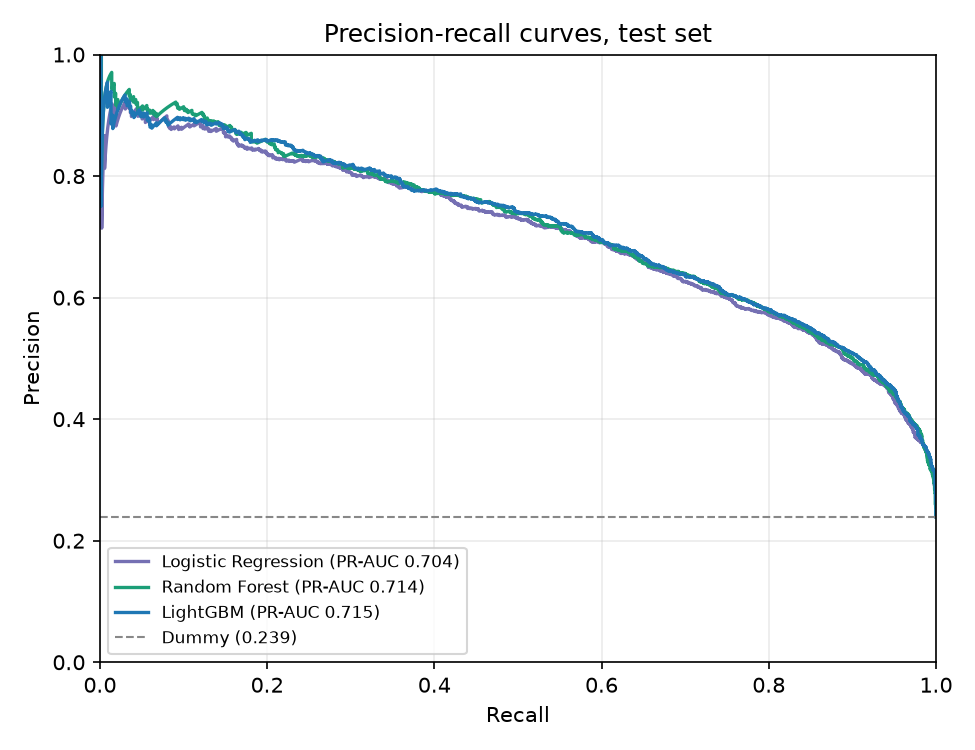

In [2]:
models = pd.DataFrame(res["models"])
cols = ["pr_auc", "roc_auc", "brier", "ece", "top_bin_predicted", "top_bin_observed"]
table = models.pivot(index="model", columns="split", values=["pr_auc", "roc_auc", "brier", "ece"])
table = table.reindex(["Dummy (prior)", "Logistic Regression", "Random Forest", "LightGBM"])
print("Development (out-of-fold) vs test: does the development score hold?")
display(table.round(4))

ci = pd.DataFrame({m: {k: f"[{v[0]:.3f}, {v[1]:.3f}]" for k, v in d.items()}
                   for m, d in res["test_ci95"].items()}).T
print("95% bootstrap intervals on the test set (1,000 resamples of people)")
display(ci)

rows = [{"comparison": k, "metric": m, "estimate": v["estimate"],
         "ci95 low": v["ci95"][0], "ci95 high": v["ci95"][1],
         "share of resamples > 0": v["share_of_resamples_above_0"]}
        for k, d in res["paired_differences_test"].items() for m, v in d.items()]
print("Paired differences on the same test people (LightGBM minus the other model)")
display(pd.DataFrame(rows).round(4))
display(Image(str(REPORTS / "figures" / "test_pr_curves.png")))

**Reading.**
- **LightGBM v2 on the test set: PR-AUC 0.715 [0.696, 0.732], ROC-AUC 0.894,
  Brier 0.109, ECE 0.009.** The floor (Dummy) is 0.239: the model is far above
  chance, at the ceiling found on the development set.
- **The development numbers held:** PR-AUC 0.718 (out-of-fold) → 0.715 (test),
  a drop of 0.0035, inside the fold noise (± 0.013). The tuning on the same
  folds made the development score only slightly optimistic (S5). ROC-AUC and
  Brier are even marginally better on test (0.8927 → 0.8945, 0.1096 → 0.1092).
  Same for the others: logistic regression 0.708 → 0.704, random forest 0.714
  → 0.714.
- **LightGBM beats the logistic regression, for real:** +0.011 PR-AUC, 95%
  interval [+0.005, +0.016] on the same people, in 100% of the resamples; Brier
  −0.0023 [−0.0030, −0.0014]. The cost of a linear model (F37) is confirmed.
- **LightGBM and the random forest are tied on ranking:** +0.0008 PR-AUC
  [−0.004, +0.005]; LightGBM has a slightly better Brier (−0.0007, interval
  [−0.0013, −0.00001], just excluding 0). The choice of LightGBM rests on its
  probabilities and its smaller gap (F39), not on a ranking advantage.
- **The intervals of the three models overlap** (PR-AUC about [0.68, 0.73]):
  on 9,758 people, a single test score is uncertain by about ± 0.02. Paired
  differences are the right way to compare models on the same test set.

## 2. Calibration of LightGBM v2 on the test set

,variant,group,brier,ece,mean_predicted,observed_rate,top_bin_predicted,top_bin_observed
0,raw,all,0.1092,0.0091,0.2401,0.2394,0.8140,0.8033
1,raw,Female,0.0622,0.0127,0.1126,0.1092,0.5807,0.5920
2,raw,Male,0.1328,0.0118,0.3041,0.3047,0.8411,0.8415
3,platt,all,0.1092,0.0092,0.2401,0.2394,0.8142,0.8033
4,platt,Female,0.0622,0.0126,0.1125,0.1092,0.5807,0.5920
5,platt,Male,0.1328,0.0119,0.3041,0.3047,0.8413,0.8415


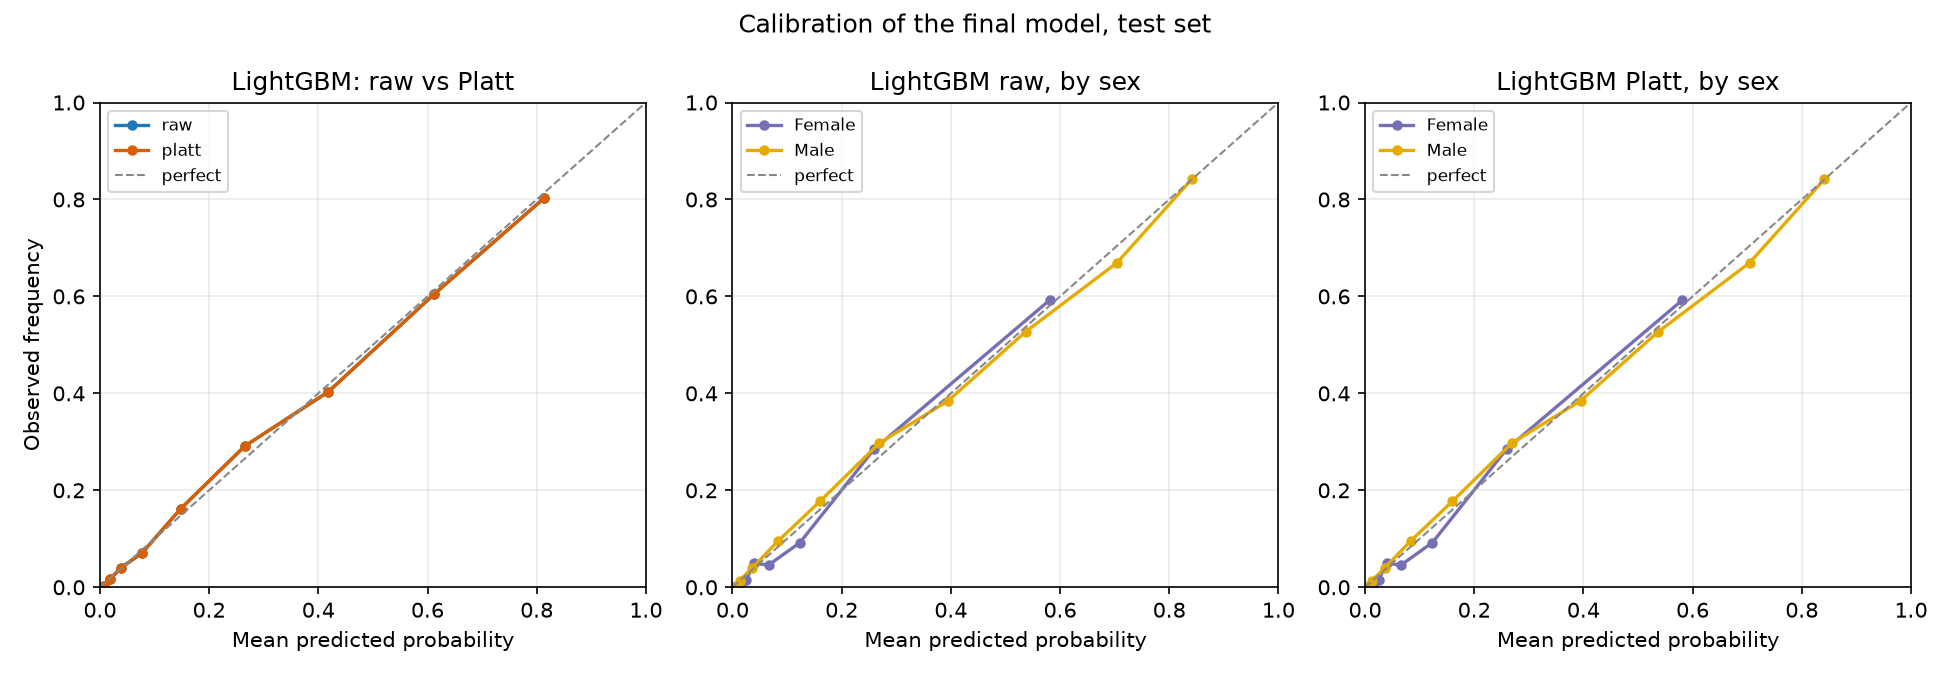

In [3]:
calib = pd.DataFrame(res["calibration_test"])
display(calib[["variant", "group", "brier", "ece", "mean_predicted", "observed_rate",
               "top_bin_predicted", "top_bin_observed"]].round(4))
display(Image(str(REPORTS / "figures" / "test_calibration.png")))

**Reading.**
- **Still calibrated on new people:** ECE 0.009 (development 0.006), mean
  predicted 0.240 vs observed 0.239; in the top 10%, 0.814 predicted vs 0.803
  observed.
- **By sex:** women 0.113 predicted vs 0.109 observed, men 0.304 vs 0.305; ECE
  0.013 and 0.012 (fewer people per bin than on development, so slightly
  noisier). A score means the same for women and men on average.
- **Platt changes nothing** (ECE 0.0092 vs 0.0091, same Brier 0.1092): the
  decision of F41 (no recalibration needed) holds on the test set.

## 3. Fairness by sex: before and after the mitigation, on the test set

Same definitions and rules as the development audit (`notebooks/06_fairness.ipynb`):
primary = equalized odds, legal screen = four-fifths rule. The thresholds and
the `ThresholdOptimizer` were fixed on the development set and are only
**applied** here. Test set: 3,259 women (10.9% high earners), 6,499 men (30.5%).

Thresholds fixed on the development set: {'best_f1': 0.343, 'best_balanced_accuracy': 0.208}

Test set, women vs men: single threshold (best F1)


,n,selection_rate,tpr,fpr,ppv,base_rate
group,,,,,,
Female,3259.0,0.110,0.570,0.054,0.564,0.109
Male,6499.0,0.392,0.785,0.220,0.610,0.305



Test set, women vs men: single threshold (best balanced accuracy)


,n,selection_rate,tpr,fpr,ppv,base_rate
group,,,,,,
Female,3259.0,0.179,0.753,0.108,0.460,0.109
Male,6499.0,0.502,0.893,0.331,0.542,0.305



Test set, women vs men: equalized odds (ThresholdOptimizer)


...

,rule,accuracy,balanced_accuracy,f1,precision,recall
0,single threshold (best F1),0.823,0.799,0.670,0.604,0.752
1,single threshold (best balanced accuracy),0.784,0.814,0.659,0.530,0.872
2,equalized odds (ThresholdOptimizer),0.766,0.785,0.627,0.507,0.822
3,equal opportunity (ThresholdOptimizer),0.789,0.809,0.658,0.538,0.846
4,demographic parity (ThresholdOptimizer),0.757,0.775,0.614,0.496,0.808


Fairness gaps on the test set (women minus men; four-fifths ratio = women / men)


,rule,dp_diff,tpr_diff,fpr_diff,equalized_odds_gap,ppv_diff,four_fifths_ratio
0,single threshold (best F1),-0.282,-0.215,-0.166,0.215,-0.046,0.282
1,single threshold (best balanced accuracy),-0.323,-0.140,-0.222,0.222,-0.082,0.356
2,equalized odds (ThresholdOptimizer),-0.108,0.004,0.003,0.004,-0.304,0.745
3,equal opportunity (ThresholdOptimizer),-0.211,0.003,-0.111,0.111,-0.183,0.528
4,demographic parity (ThresholdOptimizer),-0.007,0.137,0.100,0.137,-0.349,0.983


95% bootstrap intervals of the gaps on the test set (500 resamples)


,tpr_diff,fpr_diff,dp_diff,four_fifths_ratio
single threshold (best F1),"[-0.272, -0.164]","[-0.180, -0.151]","[-0.298, -0.266]","[0.253, 0.309]"
single threshold (best balanced accuracy),"[-0.186, -0.093]","[-0.241, -0.207]","[-0.342, -0.306]","[0.328, 0.384]"
equalized odds (ThresholdOptimizer),"[-0.042, 0.047]","[-0.017, 0.024]","[-0.128, -0.086]","[0.702, 0.793]"


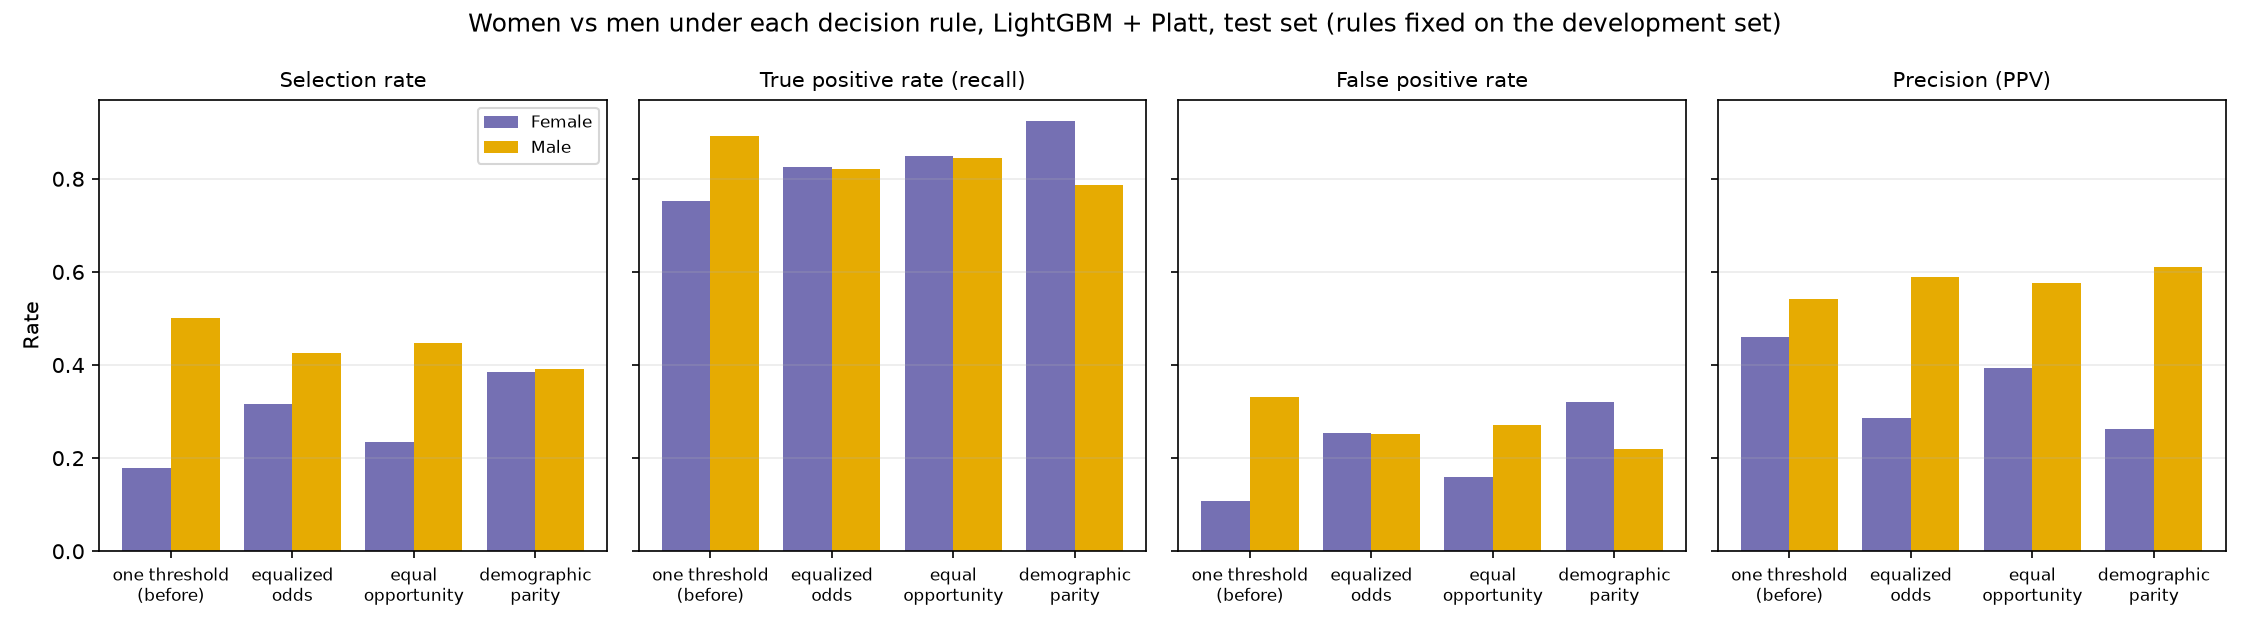

In [4]:
fair = res["fairness_test"]
print("Thresholds fixed on the development set:",
      {k: round(v, 3) for k, v in fair["thresholds_from_development"].items()})
for rule in ["single threshold (best F1)", "single threshold (best balanced accuracy)",
             "equalized odds (ThresholdOptimizer)"]:
    print(f"\nTest set, women vs men: {rule}")
    display(pd.DataFrame(fair["by_sex"][rule]).set_index("group").round(3))
rules = pd.DataFrame(fair["rules"])
print("Performance of each decision rule (all test people)")
display(rules[["rule", "accuracy", "balanced_accuracy", "f1", "precision", "recall"]].round(3))
print("Fairness gaps on the test set (women minus men; four-fifths ratio = women / men)")
display(rules[["rule", "dp_diff", "tpr_diff", "fpr_diff", "equalized_odds_gap", "ppv_diff",
               "four_fifths_ratio"]].round(3))
iv = pd.DataFrame({rule: {k: f"[{v[0]:.3f}, {v[1]:.3f}]" for k, v in d.items()}
                   for rule, d in fair["bootstrap_95"].items()}).T
print("95% bootstrap intervals of the gaps on the test set (500 resamples)")
display(iv)
display(Image(str(REPORTS / "figures" / "test_fairness_by_sex.png")))

**Reading: before the mitigation.**
- **At the best-F1 threshold (0.343), the model finds 57.0% of the
  high-earning women vs 78.5% of the men** (TPR gap −0.215, interval [−0.272,
  −0.164]) and wrongly flags 5.4% of the women under $50K vs 22.0% of the men
  (FPR gap −0.166): equalized-odds gap 0.215 (development 0.194).
- **It flags 11.0% of the women vs 39.2% of the men:** four-fifths ratio
  **0.28** [0.25, 0.31], far below the 0.8 screen (development 0.27).
- **A flag means almost the same:** PPV 0.564 vs 0.610 (gap −0.046; development
  −0.007). The test gap is larger but rests on only about 360 flagged women,
  so it is less precise.

**Reading: after the mitigation (equalized odds, per-sex thresholds).**
- **The error-rate gaps disappear on new people:** TPR 0.826 vs 0.822 (gap
  +0.004, interval [−0.042, +0.047]), FPR 0.254 vs 0.251 (+0.003, [−0.017,
  +0.024]). Both intervals contain 0: the mitigation fixed on the development
  set **generalises**.
- **Cost** (vs the balanced-accuracy threshold, the same objective): balanced
  accuracy 0.814 → 0.785, accuracy 0.784 → 0.766, F1 0.659 → 0.627, precision
  0.530 → 0.507. Development: 0.812 → 0.783.
- **Four-fifths ratio 0.36 → 0.75** [0.70, 0.79]: much closer, still under
  0.8.
- **Precision gap opens:** 0.285 for women vs 0.589 for men (−0.304;
  development −0.298). The S9 impossibility, again on the test set.
- **Sensitivity:** equal opportunity closes only the TPR gap (FPR gap −0.111
  remains); demographic parity reaches a ratio of 0.98 but opens a TPR gap of
  +0.137 and a precision gap of −0.349.

In [5]:
print("Test set, by race at the best-F1 threshold (groups under 500 people are unstable)")
display(pd.DataFrame(fair["by_race_best_f1"]).set_index("group").round(3))

Test set, by race at the best-F1 threshold (groups under 500 people are unstable)


,n,selection_rate,tpr,fpr,ppv,base_rate,small_group
group,,,,,,,
Amer-Indian-Eskimo,87.0,0.230,0.538,0.176,0.350,0.149,True
Asian-Pac-Islander,311.0,0.357,0.772,0.183,0.640,0.296,True
Black,899.0,0.132,0.722,0.061,0.588,0.108,False
Other,80.0,0.162,0.800,0.071,0.615,0.125,True
White,8381.0,0.316,0.754,0.167,0.605,0.253,False


**By race (test set).** Black people (899) are flagged less than White people
(13.2% vs 31.6%; base rates 10.8% vs 25.3%), with a lower TPR (0.722 vs 0.754)
and FPR (0.061 vs 0.167). In the test set, only White and Black have 500
people or more; the other groups (80 to 311 people) give unstable rates and are
not interpreted.

## 4. Explainability on the test set: where the score gap comes from

In [6]:
shap_test = pd.DataFrame(res["shap_test"]["by_input"]).set_index("input")
gap = res["shap_test"]["score_gap_by_sex"]
shap_test["share of the gap"] = shap_test["gap_women_minus_men"] / gap["score_gap"]
dev = pd.DataFrame(json.loads((REPORTS / "shap_dev.json").read_text())["by_input"]).set_index("input")
shap_test["share on development"] = dev["gap_women_minus_men"] / dev["gap_women_minus_men"].sum()
print(f"Mean score (log-odds) on the test set: women {gap['mean_score_women']:.3f}, "
      f"men {gap['mean_score_men']:.3f}, gap {gap['score_gap']:.3f}")
display(shap_test.round(3))

Mean score (log-odds) on the test set: women -3.319, men -1.648, gap -1.671


,mean_abs,mean_women,mean_men,gap_women_minus_men,share of the gap,share on development
input,,,,,,
marital-status,1.193,-0.719,0.363,-1.081,0.647,0.658
age,0.744,-0.154,0.066,-0.220,0.132,0.136
education-num,0.518,-0.014,0.019,-0.033,0.019,0.014
hours-per-week,0.359,-0.165,0.081,-0.246,0.148,0.145
occupation,0.345,-0.049,0.014,-0.064,0.038,0.034
workclass,0.080,-0.016,0.010,-0.027,0.016,0.012


**Reading.** The final model (fitted on the whole development set) gives
women a mean score 1.67 log-odds lower than men on the test set (development
1.65). SHAP splits it the same way as on the development set: **marital status
65%**, hours 15%, age 13%, occupation 4%, education 2%, workclass 2%. The
proxy structure found in notebook 05 (F43) is a property of the model, not of
the folds.

## 5. Model card (final model)

| Item | |
|---|---|
| **Model** | LightGBM, tuned v2 (950 trees, learning rate 0.014, 12 leaves, no class weight), in the project Pipeline (feature engineering + preprocessing); fitted on the 39,032 people of the development set |
| **Task** | Predict whether a person earns more than $50K a year (1994 US Census, UCI Adult) |
| **Intended use** | The model-audit step of a company whose clients use such predictions (e.g. to choose whom to audit): measure the bias by sex, reduce part of it and show the cost. Not for decisions about real people as is: 1994 data, US only |
| **Inputs** | age, workclass, education-num, marital-status, occupation, hours-per-week. **Never inputs:** sex, race, native-country (audit only); capital gains / losses dropped (leakage, F4) |
| **Test performance** | PR-AUC 0.715 [0.696, 0.732] (floor 0.239), ROC-AUC 0.894, Brier 0.109, ECE 0.009; better than the logistic regression benchmark (+0.011 PR-AUC, interval excludes 0), tied with the random forest |
| **Calibration** | Calibrated without recalibration, overall and by sex (women 0.113 predicted vs 0.109 observed; men 0.304 vs 0.305) |
| **Fairness (one threshold, best F1)** | Women: TPR 0.570, FPR 0.054, selected 11.0%; men: TPR 0.785, FPR 0.220, selected 39.2%. Equalized-odds gap 0.215; four-fifths ratio 0.28; PPV 0.564 vs 0.610 |
| **Mitigation (equalized odds, per-sex thresholds)** | Gaps not distinguishable from 0 on the test set (TPR +0.004, FPR +0.003); costs about 0.03 balanced accuracy; four-fifths ratio 0.75; precision gap −0.30 |
| **Why the gap exists** | The inputs are proxies for sex: two thirds of the score gap goes through marital status, then hours and age (SHAP, F43); the base rates differ (10.9% vs 30.5%) |
| **Limitations** | 1994 data; six inputs (ceiling about 0.72 PR-AUC for every model); per-sex thresholds use sex at decision time, which is a policy and legal decision (F29); the fairness definitions conflict (S9), so the choice of equalized odds must be stated; small race groups cannot be audited reliably |

## 6. Findings

1. **The development results hold on new people.** LightGBM v2: test PR-AUC
   0.715 (development 0.718), ROC-AUC 0.894, Brier 0.109: the tuning was only
   slightly optimistic.
2. **LightGBM is better than the logistic regression** (+0.011 PR-AUC, paired
   interval [+0.005, +0.016]) **and tied with the random forest** on ranking;
   it has the best probabilities.
3. **It stays calibrated**, overall (ECE 0.009) and by sex; Platt changes
   nothing.
4. **The bias by sex is confirmed:** at one threshold, women's high earners
   are found less often (TPR 0.570 vs 0.785) and women are selected far less
   (four-fifths ratio 0.28).
5. **The mitigation fixed on the development set works on the test set:**
   equalized odds brings both error-rate gaps to about 0 (intervals contain 0)
   for about 0.03 balanced accuracy, and opens the precision gap (−0.30).
6. **The proxy explanation is stable:** two thirds of the score gap goes
   through marital status on the test set too.

Details: finding F44 and section 3f of `docs/findings_log.md`.